In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import random

data = pd.read_csv('../data/Task2/seeds_data.csv')

In [ ]:
data

In [ ]:
data.info()
data.describe()

In [2]:
data.Class.value_counts()

Class
1    70
2    70
3    70
Name: count, dtype: int64

In [3]:
class KMeans:
    class Cluster:
        def __init__(self, model: KMeans):
            self.model = model
            self.indices = list()
        def add(self, index: int):
            self.indices.append(index)
        def retrieve(self):
            return self.model.data[self.indices,:]
        def reset(self):
            self.indices.clear()
        def mean(self):
            return self.retrieve().mean(axis=0)
        def wcss(self):
            return self.retrieve().var(axis=0).sum()

    def __init__(self, data: pd.DataFrame, k=3):
        self.data = data.to_numpy()
        self.k = k
    def __distance(self, a, b):
        return np.linalg.norm(a-b)

    def run(self) -> list[Cluster]:
        # random initial centroids
        centroids = self.data[random.sample(range(self.data.shape[0]), self.k)]
        clusters = [self.Cluster(self) for _ in range(self.k)]
        n = 1
        while True:
            old_centroids = centroids.copy()
            for c in clusters:
                c.reset()
            for idx in range(self.data.shape[0]):
                # compute distance from every cluster's centroid
                dists = list(map(lambda centroid: self.__distance(self.data[idx], centroid), centroids))
                # add to the closest cluster
                clusters[np.argmin(dists)].add(idx)
            centroids = np.array([c.mean() for c in clusters])
            if np.all(old_centroids == centroids):
                break
            n += 1
        return clusters

    # tries clustering multiple times to get the one with the lowest variance sum
    def cluster(self, N=5):
        var_sums = list()
        list_of_clusters = list()
        for i in range(N):
            clusters = model.run()
            var_sums.append(sum([c.wcss() for c in clusters]))
            list_of_clusters.append(clusters)
        return list_of_clusters[np.argmin(var_sums)]

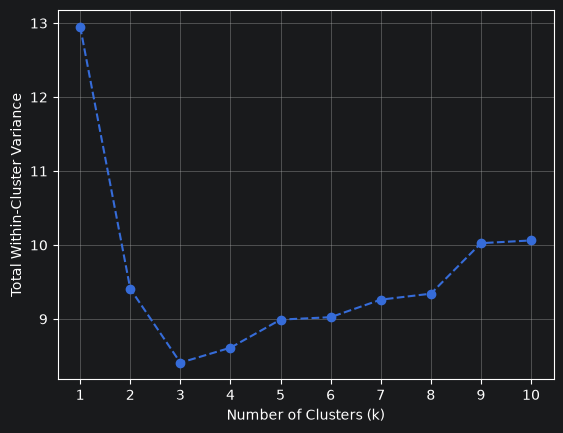

In [4]:
model = KMeans(data.drop(columns=['Class']))
y = list()
for k in range(1, 11):
    model.k = k
    var_sum = sum(c.wcss() for c in model.cluster())
    y.append(var_sum)
plt.plot(range(1, 11), y, marker='o', linestyle='--')
plt.xticks(range(1, 11))
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Total Within-Cluster Variance')
plt.grid()
plt.show()

In [5]:
model.k = 3
clusters = model.cluster()

for c in clusters:
    print(data.Class[c.indices].to_list())

[1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]
[1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3]
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3]
